<a href="https://colab.research.google.com/github/MG3191/Smart-Electricity-Consumption-Prediction/blob/main/Electricity_Consumption_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- 1. First 5 Rows of Dataset ---


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,01/01/2010,00:00:00,1.780,0.129,242.39,6.96,0.0,0.0,1.1
1,01/01/2010,01:00:00,1.751,0.054,240.36,7.18,0.0,0.0,0.1
2,01/01/2010,02:00:00,1.853,0.127,242.87,6.12,30.0,0.0,0.9
3,01/01/2010,03:00:00,1.243,0.145,245.67,5.75,0.0,0.0,1.6
4,01/01/2010,04:00:00,0.886,0.146,240.05,3.74,0.0,0.0,1.2



--- 2. Model Performance Comparison ---


,Model,MSE,RMSE,R2 Score
0,Multiple Linear Regression,0.0067,0.0816,0.9419
1,AdaBoost Regressor,0.0085,0.0923,0.9256
2,Random Forest Regressor,0.0074,0.0859,0.9356
3,Gradient Boosting Regressor,0.0071,0.0840,0.9384


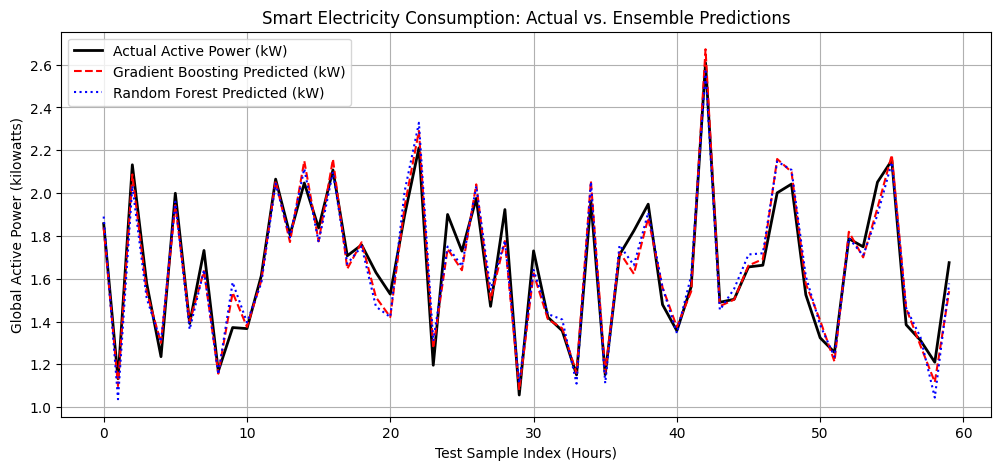

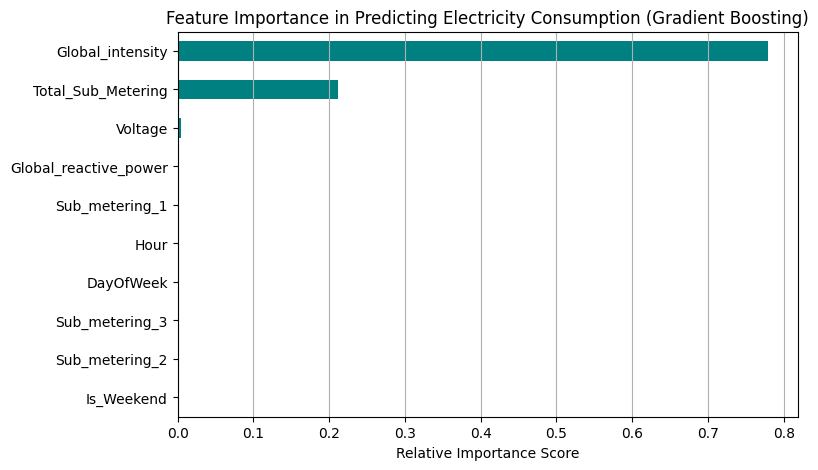

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)
n_samples = 2000

dates = pd.date_range(start='2010-01-01', periods=n_samples, freq='h')
voltage = np.random.normal(loc=240.8, scale=3.2, size=n_samples)
hour = dates.hour


base_intensity = 4.5 + 3.0 * np.sin((hour - 6) * np.pi / 12)**2 + np.random.normal(0, 0.8, n_samples)
global_intensity = np.clip(base_intensity, 0.8, 25.0)

sub_1 = np.random.choice([0.0, 1.0, 2.0, 15.0, 30.0], size=n_samples, p=[0.7, 0.1, 0.1, 0.05, 0.05])
sub_2 = np.random.choice([0.0, 1.0, 2.0, 10.0, 25.0], size=n_samples, p=[0.65, 0.15, 0.1, 0.05, 0.05])
sub_3 = np.where((hour >= 6) & (hour <= 22), np.random.uniform(5, 18, n_samples), np.random.uniform(0, 3, n_samples))
reactive_power = np.clip(np.random.normal(0.12, 0.05, n_samples), 0.0, 0.8)

active_power = (voltage * global_intensity) / 1000.0 + 0.015 * (sub_1 + sub_2 + sub_3) + np.random.normal(0, 0.08, n_samples)

df_raw = pd.DataFrame({
    'Date': dates.strftime('%d/%m/%Y'),
    'Time': dates.strftime('%H:%M:%S'),
    'Global_active_power': np.round(active_power, 3),
    'Global_reactive_power': np.round(reactive_power, 3),
    'Voltage': np.round(voltage, 2),
    'Global_intensity': np.round(global_intensity, 2),
    'Sub_metering_1': np.round(sub_1, 1),
    'Sub_metering_2': np.round(sub_2, 1),
    'Sub_metering_3': np.round(sub_3, 1)
})


df_raw.to_csv('household_power_consumption.csv', index=False)

df = pd.read_csv('household_power_consumption.csv')
print("--- 1. First 5 Rows of Dataset ---")
display(df.head())

df.dropna(inplace=True)

df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S')
df['Hour'] = df['Datetime'].dt.hour
df['DayOfWeek'] = df['Datetime'].dt.dayofweek
df['Is_Weekend'] = df['DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)
df['Total_Sub_Metering'] = df['Sub_metering_1'] + df['Sub_metering_2'] + df['Sub_metering_3']

# Select Features (X) and Target (y)
features = ['Global_reactive_power', 'Voltage', 'Global_intensity',
            'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3',
            'Hour', 'DayOfWeek', 'Is_Weekend', 'Total_Sub_Metering']
X = df[features]
y = df['Global_active_power']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Multiple Linear Regression": LinearRegression(),
    "AdaBoost Regressor": AdaBoostRegressor(n_estimators=100, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting Regressor": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results.append({"Model": name, "MSE": round(mse, 4), "RMSE": round(rmse, 4), "R2 Score": round(r2, 4)})

results_df = pd.DataFrame(results)
print("\n--- 2. Model Performance Comparison ---")
display(results_df)

plt.figure(figsize=(12, 5))
plt.plot(y_test.values[:60], label='Actual Active Power (kW)', color='black', linewidth=2)
plt.plot(predictions["Gradient Boosting Regressor"][:60], label='Gradient Boosting Predicted (kW)', linestyle='--', color='red')
plt.plot(predictions["Random Forest Regressor"][:60], label='Random Forest Predicted (kW)', linestyle=':', color='blue')
plt.title('Smart Electricity Consumption: Actual vs. Ensemble Predictions')
plt.xlabel('Test Sample Index (Hours)')
plt.ylabel('Global Active Power (kilowatts)')
plt.legend()
plt.grid(True)
plt.show()

gb_model = models["Gradient Boosting Regressor"]
importances = pd.Series(gb_model.feature_importances_, index=features).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importances.plot(kind='barh', color='teal')
plt.title('Feature Importance in Predicting Electricity Consumption (Gradient Boosting)')
plt.xlabel('Relative Importance Score')
plt.grid(axis='x')
plt.show()

--- 1. First 5 Rows of Dataset ---


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,01/01/2010,00:00:00,1.780,0.129,242.39,6.96,0.0,0.0,1.1
1,01/01/2010,01:00:00,1.751,0.054,240.36,7.18,0.0,0.0,0.1
2,01/01/2010,02:00:00,1.853,0.127,242.87,6.12,30.0,0.0,0.9
3,01/01/2010,03:00:00,1.243,0.145,245.67,5.75,0.0,0.0,1.6
4,01/01/2010,04:00:00,0.886,0.146,240.05,3.74,0.0,0.0,1.2



--- 2. Model Performance Comparison ---


,Model,MSE,RMSE,R2 Score
0,Multiple Linear Regression,0.0067,0.0816,0.9419
1,AdaBoost Regressor,0.0085,0.0923,0.9256
2,Random Forest Regressor,0.0074,0.0859,0.9356
3,Gradient Boosting Regressor,0.0071,0.0840,0.9384


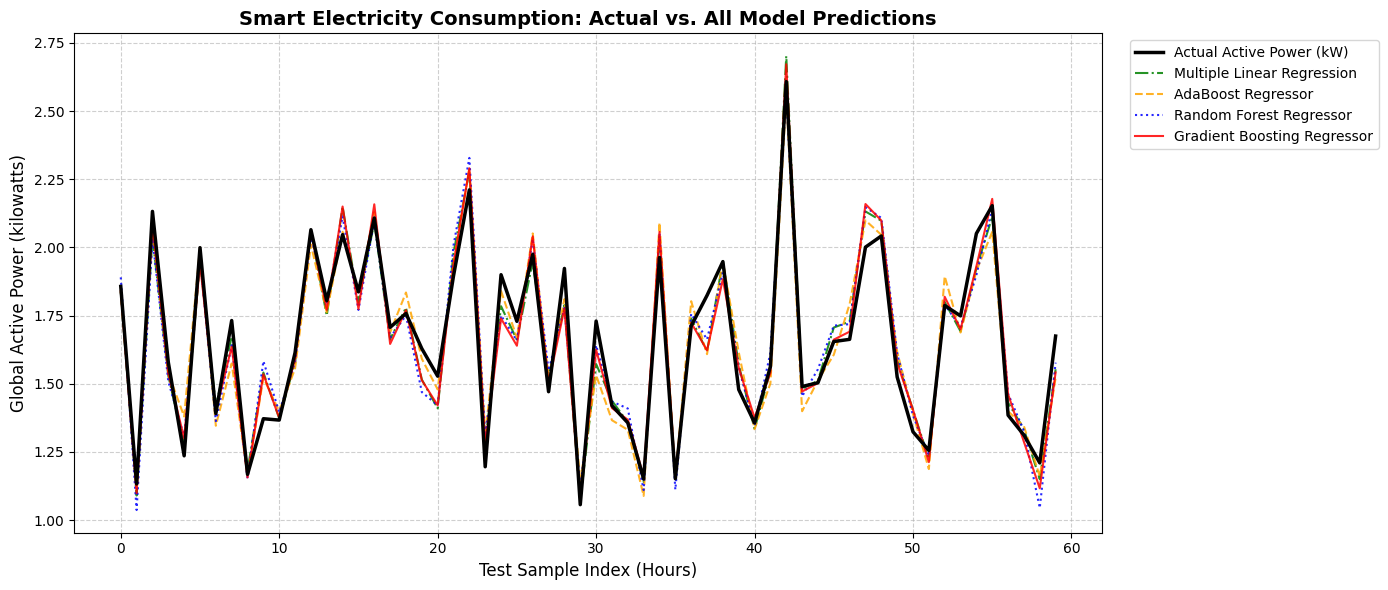

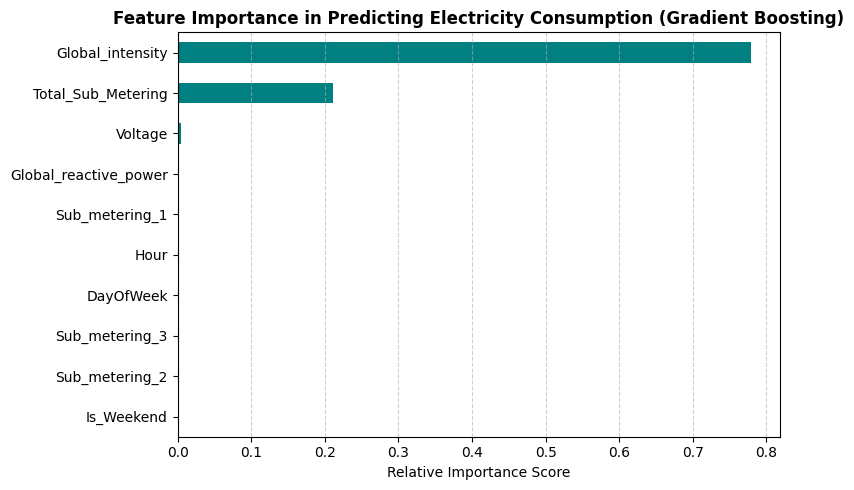

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)
n_samples = 2000

dates = pd.date_range(start='2010-01-01', periods=n_samples, freq='h')
voltage = np.random.normal(loc=240.8, scale=3.2, size=n_samples)
hour = dates.hour

# Fixed syntax from the original code snippet
base_intensity = 4.5 + 3.0 * np.sin((hour - 6) * np.pi / 12)**2 + np.random.normal(0, 0.8, n_samples)
global_intensity = np.clip(base_intensity, 0.8, 25.0)

sub_1 = np.random.choice([0.0, 1.0, 2.0, 15.0, 30.0], size=n_samples, p=[0.7, 0.1, 0.1, 0.05, 0.05])
sub_2 = np.random.choice([0.0, 1.0, 2.0, 10.0, 25.0], size=n_samples, p=[0.65, 0.15, 0.1, 0.05, 0.05])
sub_3 = np.where((hour >= 6) & (hour <= 22), np.random.uniform(5, 18, n_samples), np.random.uniform(0, 3, n_samples))
reactive_power = np.clip(np.random.normal(0.12, 0.05, n_samples), 0.0, 0.8)

# Fixed syntax for active power calculation
active_power = (voltage * global_intensity) / 1000.0 + 0.015 * (sub_1 + sub_2 + sub_3) + np.random.normal(0, 0.08, n_samples)

df_raw = pd.DataFrame({
    'Date': dates.strftime('%d/%m/%Y'),
    'Time': dates.strftime('%H:%M:%S'),
    'Global_active_power': np.round(active_power, 3),
    'Global_reactive_power': np.round(reactive_power, 3),
    'Voltage': np.round(voltage, 2),
    'Global_intensity': np.round(global_intensity, 2),
    'Sub_metering_1': np.round(sub_1, 1),
    'Sub_metering_2': np.round(sub_2, 1),
    'Sub_metering_3': np.round(sub_3, 1)
})

df_raw.to_csv('household_power_consumption.csv', index=False)

df = pd.read_csv('household_power_consumption.csv')
print("--- 1. First 5 Rows of Dataset ---")
display(df.head())

df.dropna(inplace=True)

df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S')
df['Hour'] = df['Datetime'].dt.hour
df['DayOfWeek'] = df['Datetime'].dt.dayofweek
df['Is_Weekend'] = df['DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)
df['Total_Sub_Metering'] = df['Sub_metering_1'] + df['Sub_metering_2'] + df['Sub_metering_3']

# Select Features (X) and Target (y)
features = ['Global_reactive_power', 'Voltage', 'Global_intensity',
            'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3',
            'Hour', 'DayOfWeek', 'Is_Weekend', 'Total_Sub_Metering']
X = df[features]
y = df['Global_active_power']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Multiple Linear Regression": LinearRegression(),
    "AdaBoost Regressor": AdaBoostRegressor(n_estimators=100, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting Regressor": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results.append({"Model": name, "MSE": round(mse, 4), "RMSE": round(rmse, 4), "R2 Score": round(r2, 4)})

results_df = pd.DataFrame(results)
print("\n--- 2. Model Performance Comparison ---")
display(results_df)

# --- Updated Graph Section: Comparing Actual vs. All Models ---
plt.figure(figsize=(14, 6))

# Plot Actual Values
plt.plot(y_test.values[:60], label='Actual Active Power (kW)', color='black', linewidth=2.5, zorder=5)

# Define unique styles for each model
model_styles = {
    "Multiple Linear Regression": {"color": "green", "linestyle": "-."},
    "AdaBoost Regressor": {"color": "orange", "linestyle": "--"},
    "Random Forest Regressor": {"color": "blue", "linestyle": ":"},
    "Gradient Boosting Regressor": {"color": "red", "linestyle": "-"}
}

# Loop through all models to plot their predictions
for name, preds in predictions.items():
    style = model_styles.get(name, {"color": None, "linestyle": "-"})
    plt.plot(
        preds[:60],
        label=f'{name}',
        color=style["color"],
        linestyle=style["linestyle"],
        linewidth=1.5,
        alpha=0.85
    )

plt.title('Smart Electricity Consumption: Actual vs. All Model Predictions', fontsize=14, fontweight='bold')
plt.xlabel('Test Sample Index (Hours)', fontsize=12)
plt.ylabel('Global Active Power (kilowatts)', fontsize=12)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# --- Feature Importance Graph ---
gb_model = models["Gradient Boosting Regressor"]
importances = pd.Series(gb_model.feature_importances_, index=features).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importances.plot(kind='barh', color='teal')
plt.title('Feature Importance in Predicting Electricity Consumption (Gradient Boosting)', fontsize=12, fontweight='bold')
plt.xlabel('Relative Importance Score', fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()